In [32]:
# --- setup -----------------------------------------------------------------------------------------------
from pathlib import Path
import sqlite3, json
import pandas as pd
import matplotlib.pyplot as plt

# project root = the folder that contains configs/kg.yaml (works from notebooks/ or from the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "kg.yaml").exists())
DB = ROOT / "data" / "kg" / "kg.sqlite"

# read-only connection: the running pipeline keeps writing, we only read
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)

def q(sql, params=()):
    """Run a query and return a DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

pd.set_option("display.max_colwidth", 120)
print("database:", DB, f"({DB.stat().st_size / 1e6:.1f} MB)")
print("tables:", ", ".join(q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")["name"]))

database: /Users/macbookpro/Documents/financial_rag/data/kg/kg.sqlite (19.9 MB)
tables: alerts, check_jobs, clause_edits, companies, company_roles, coverage, doc_profiles, document_directions, document_versions, documents, edges, findings, llm_calls, llm_quota, locations, nodes, proposals, runs, sqlite_sequence, step_outputs, task_events, tasks, triage, user_decisions, user_roles, users


nodes: 3,675 in 11 types   ·   edges: 5,123 in 12 types


,type,n
0,ProvisionVersion,1350
1,Provision,1207
2,Clause,639
3,Obligation,257
4,ExtractionUnit,159
5,AmendingAct,23
6,InternalDoc,15
7,ExternalAct,14
8,EntityType,5
9,Act,4


,type,n
0,VERSION_OF,1350
1,HAS_PROVISION,1204
2,HAS_CLAUSE,639
3,COVERED_BY,634
4,APPLIES_TO,397
5,AMENDED_BY,277
6,IMPOSES,267
7,REFERS_TO,151
8,UPDATES,146
9,SUPERSEDES,33


,src_type,edge_type,dst_type,n
0,ProvisionVersion,VERSION_OF,Provision,1350
1,Act,HAS_PROVISION,Provision,1204
2,InternalDoc,HAS_CLAUSE,Clause,639
3,Obligation,COVERED_BY,Clause,634
4,Obligation,APPLIES_TO,EntityType,397
5,ProvisionVersion,AMENDED_BY,AmendingAct,277
6,ProvisionVersion,IMPOSES,Obligation,267
7,ProvisionVersion,UPDATES,ProvisionVersion,146
8,Provision,REFERS_TO,Provision,114
9,Obligation,SUPERSEDES,Obligation,33


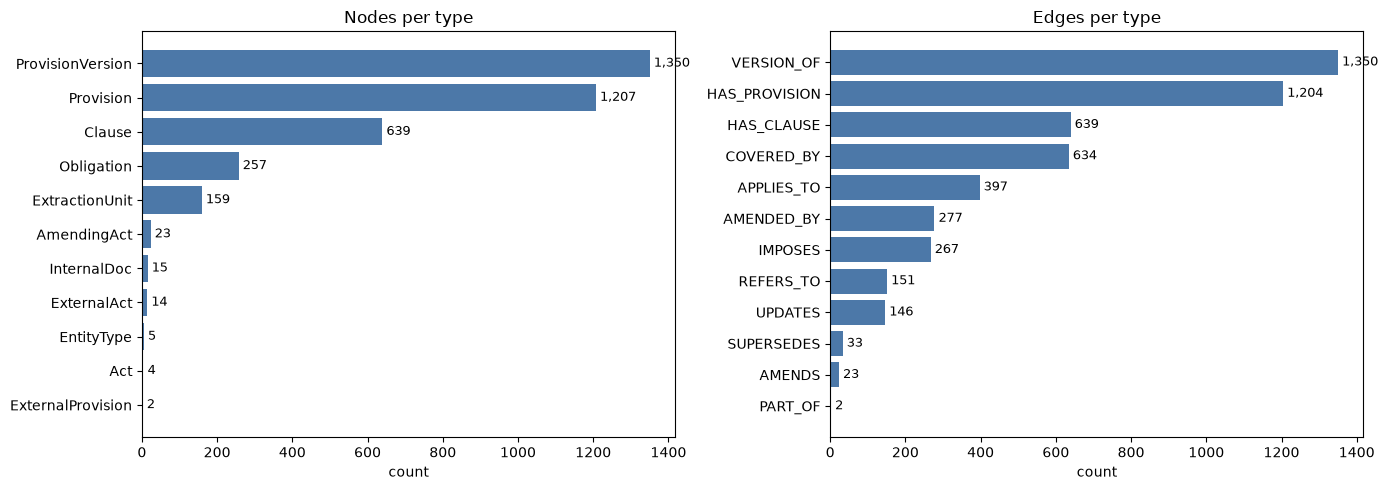

In [33]:
# --- nodes per type and edges per type --------------------------------------------------------------------
nodes = q("SELECT type, COUNT(*) AS n FROM nodes GROUP BY type ORDER BY n DESC")
edges = q("SELECT type, COUNT(*) AS n FROM edges GROUP BY type ORDER BY n DESC")

# which node types each edge type connects (e.g. Obligation -COVERED_BY-> Clause)
links = q("""
    SELECT s.type AS src_type, e.type AS edge_type, d.type AS dst_type, COUNT(*) AS n
    FROM edges e
    LEFT JOIN nodes s ON s.id = e.src
    LEFT JOIN nodes d ON d.id = e.dst
    GROUP BY 1, 2, 3 ORDER BY n DESC
""")

print(f"nodes: {nodes['n'].sum():,} in {len(nodes)} types   ·   edges: {edges['n'].sum():,} in {len(edges)} types")
display(nodes, edges, links)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, df, title in ((ax[0], nodes, "Nodes per type"), (ax[1], edges, "Edges per type")):
    bars = a.barh(df["type"], df["n"], color="#4C78A8")
    a.invert_yaxis()
    a.set_title(title)
    a.bar_label(bars, labels=[f"{v:,}" for v in df["n"]], padding=3, fontsize=9)
    a.set_xlabel("count")
plt.tight_layout()
plt.show()

3,675 nodes, 5,101 edges, 168 connected parts


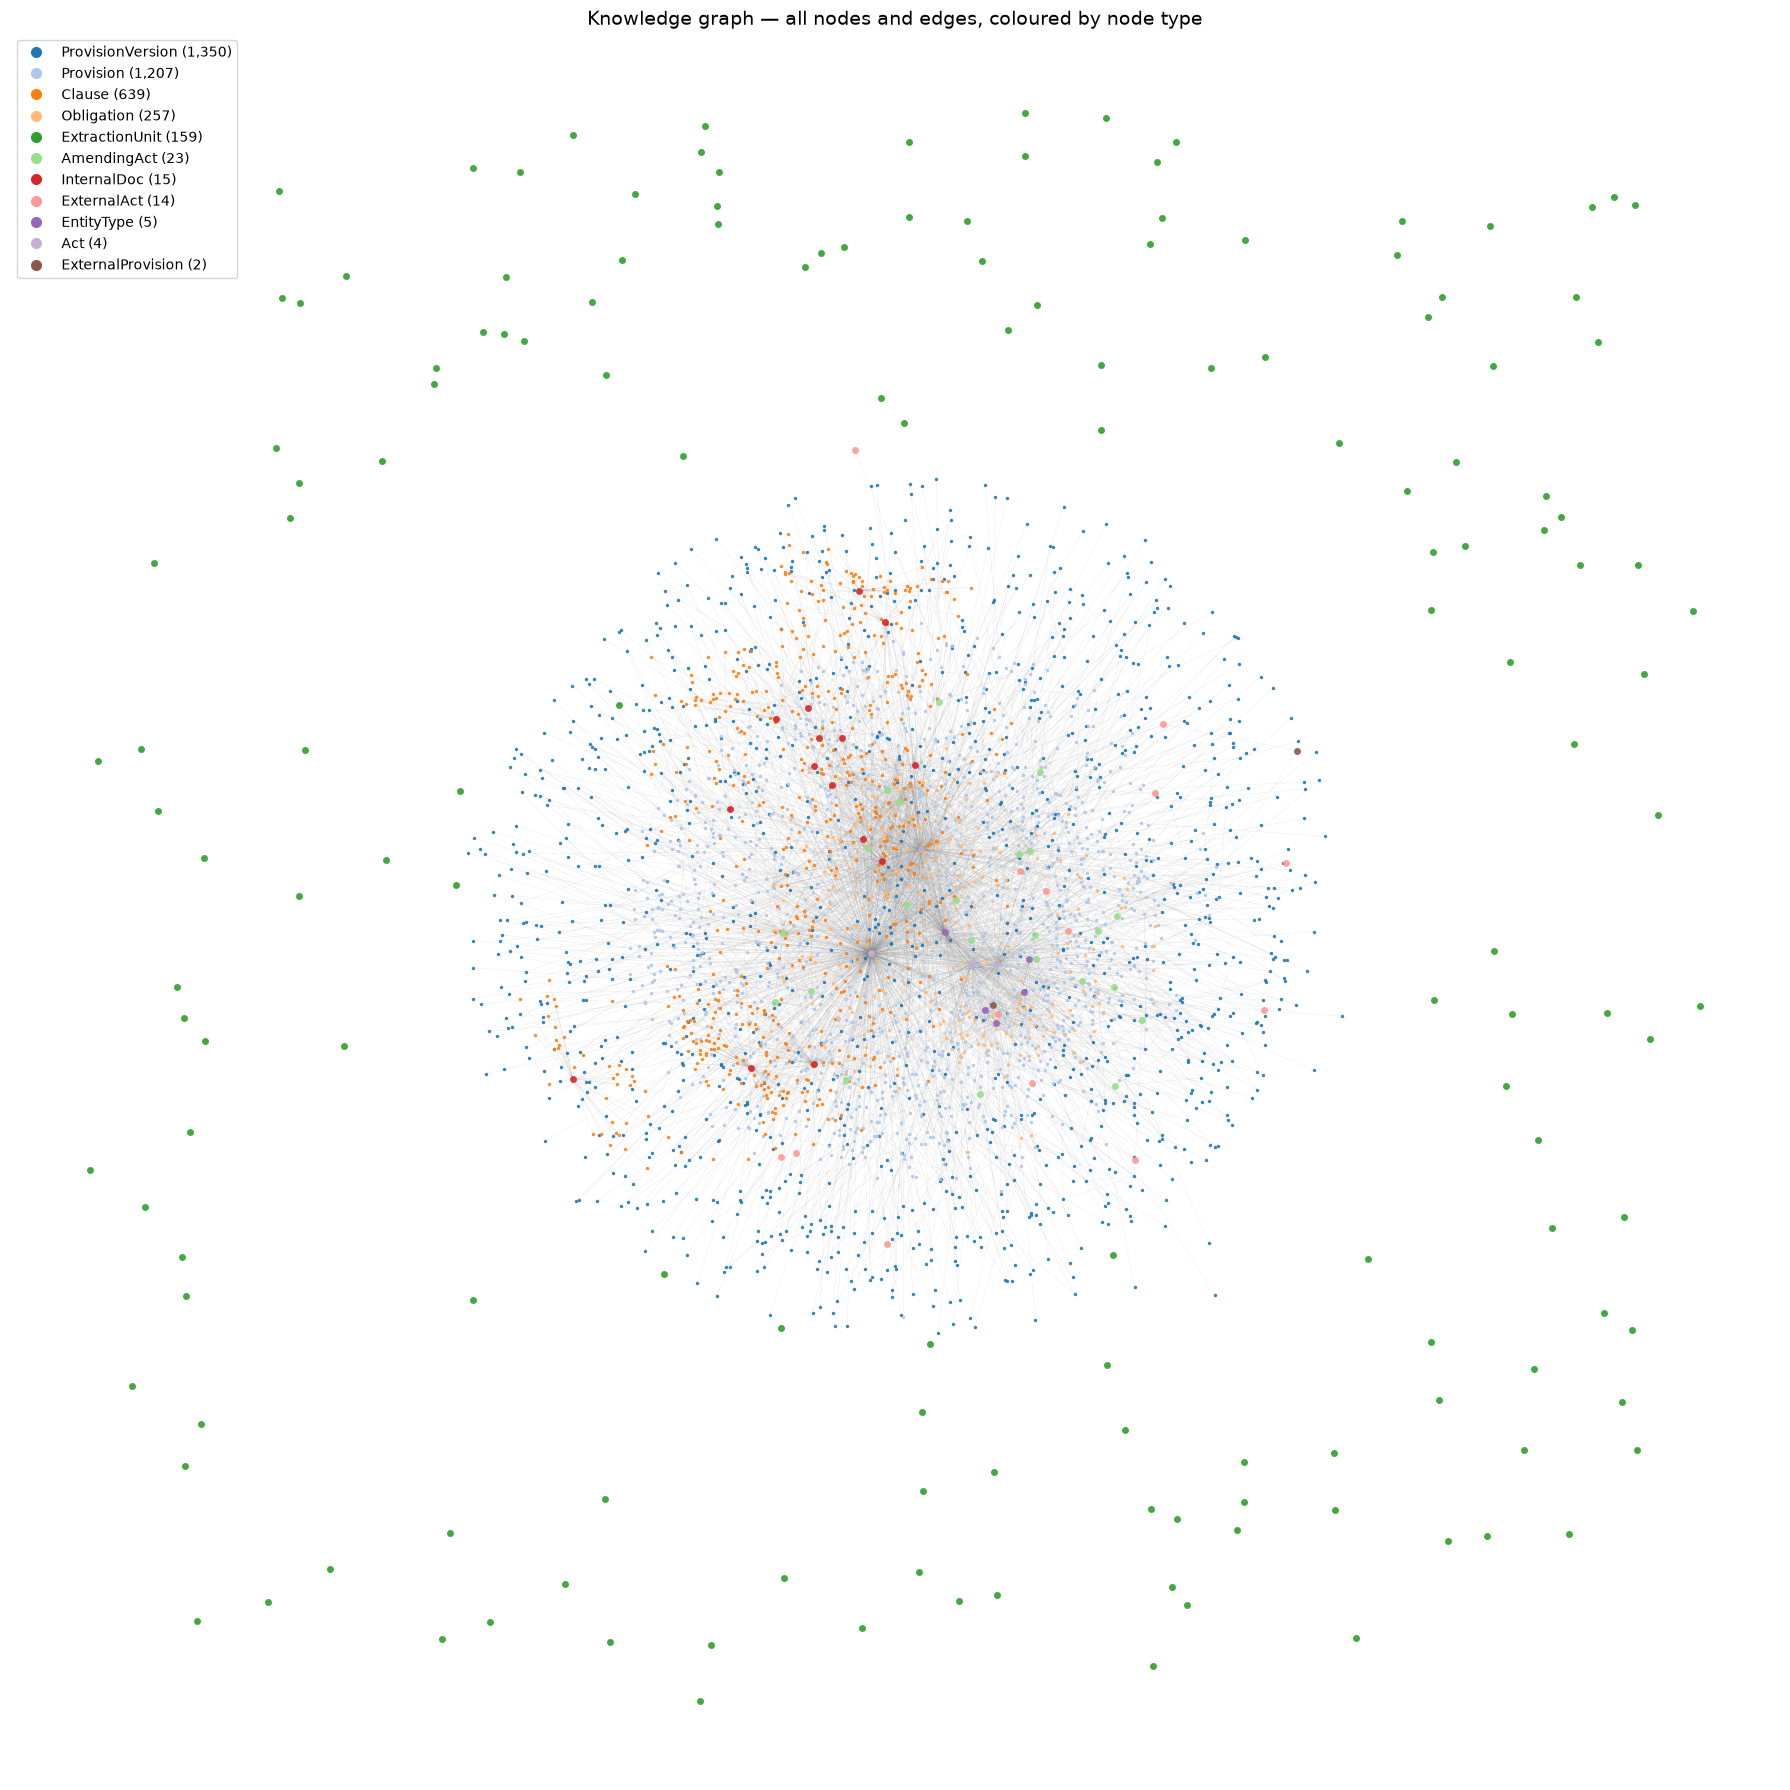

In [34]:
# --- the whole graph ----------------------------------------------------------------------------------------
import networkx as nx
from matplotlib.lines import Line2D

nd = q("SELECT id, type FROM nodes")
ed = q("SELECT src, dst, type FROM edges")

G = nx.Graph()                                   # undirected, for the layout only
G.add_nodes_from((r.id, {"type": r.type}) for r in nd.itertuples())
# edges whose end is not a node (e.g. a reference to an act outside the corpus) are left out
known = set(nd["id"])
G.add_edges_from((r.src, r.dst, {"type": r.type}) for r in ed.itertuples() if r.src in known and r.dst in known)
print(f"{G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges, "
      f"{nx.number_connected_components(G)} connected parts")

# one colour per node type
types = nd["type"].value_counts().index.tolist()
palette = plt.get_cmap("tab20").colors
color_of = {t: palette[i % len(palette)] for i, t in enumerate(types)}

pos = nx.spring_layout(G, k=0.6 / max(G.number_of_nodes(), 1) ** 0.5, iterations=60, seed=7)

fig, ax = plt.subplots(figsize=(18, 18))
nx.draw_networkx_edges(G, pos, ax=ax, width=0.2, alpha=0.25, edge_color="#888888")
for t in types:
    ids = [n for n, d in G.nodes(data=True) if d["type"] == t]
    nx.draw_networkx_nodes(G, pos, nodelist=ids, ax=ax, node_size=6 if len(ids) > 200 else 25,
                           node_color=[color_of[t]], alpha=0.9, linewidths=0)
ax.legend(handles=[Line2D([0], [0], marker="o", linestyle="", markersize=8, markerfacecolor=color_of[t],
                          markeredgewidth=0, label=f"{t} ({(nd['type'] == t).sum():,})") for t in types],
          loc="upper left", fontsize=10, frameon=True)
ax.set_title("Knowledge graph — all nodes and edges, coloured by node type", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.show()

In [49]:
# --- the graph by unique relationships (plotly) ---------------------------------------------------------------
import math
import networkx as nx
import plotly.graph_objects as go

node_counts = q("SELECT type, COUNT(*) AS n FROM nodes GROUP BY type")
links = q("""
    SELECT COALESCE(s.type, '(outside)') AS src_type, e.type AS edge_type,
           COALESCE(d.type, '(outside)') AS dst_type, COUNT(*) AS n
    FROM edges e LEFT JOIN nodes s ON s.id = e.src LEFT JOIN nodes d ON d.id = e.dst
    GROUP BY 1, 2, 3 ORDER BY n DESC
""")
count_of = dict(zip(node_counts["type"], node_counts["n"]))
types = sorted(set(links["src_type"]) | set(links["dst_type"]) | set(count_of), key=lambda t: -count_of.get(t, 0))

# layout of the node types (a small graph: one node per type)
T = nx.Graph()
T.add_nodes_from(types)
T.add_edges_from((r.src_type, r.dst_type) for r in links.itertuples() if r.src_type != r.dst_type)
pos = nx.kamada_kawai_layout(T) if T.number_of_edges() else nx.circular_layout(T)

def curve(p0, p1, bend, n=30):
    """Points of a quadratic curve from p0 to p1; ``bend`` separates parallel relationships."""
    (x0, y0), (x1, y1) = p0, p1
    mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = x1 - x0, y1 - y0
    cx, cy = mx - dy * bend, my + dx * bend
    ts = [i / n for i in range(n + 1)]
    xs = [(1 - t) ** 2 * x0 + 2 * (1 - t) * t * cx + t ** 2 * x1 for t in ts]
    ys = [(1 - t) ** 2 * y0 + 2 * (1 - t) * t * cy + t ** 2 * y1 for t in ts]
    return xs, ys

def loop(p, k, r=0.07):
    """A small loop next to a node, for relationships between nodes of the same type."""
    x, y = p
    a0 = math.pi / 2 + k * 0.9
    ts = [a0 + 2 * math.pi * i / 40 for i in range(41)]
    cx, cy = x + r * math.cos(a0), y + r * math.sin(a0)
    return [cx + r * math.cos(t) for t in ts], [cy + r * math.sin(t) for t in ts]

edge_colors = {}
palette = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2", "#FF9DA6", "#9D755D",
           "#BAB0AC", "#EECA3B", "#2F4B7C", "#A05195"]
for i, et in enumerate(links["edge_type"].unique()):
    edge_colors[et] = palette[i % len(palette)]

fig = go.Figure()
seen_pairs, max_n = {}, links["n"].max()
for r in links.itertuples():
    pair = tuple(sorted((r.src_type, r.dst_type)))
    k = seen_pairs.get(pair, 0)
    seen_pairs[pair] = k + 1
    if r.src_type == r.dst_type:
        xs, ys = loop(pos[r.src_type], k)
    else:
        sign = 1 if (r.src_type, r.dst_type) == pair else -1
        xs, ys = curve(pos[r.src_type], pos[r.dst_type], bend=sign * (0.12 + 0.12 * k))
    width = 1 + 7 * math.sqrt(r.n / max_n)
    label = f"{r.src_type} —{r.edge_type}→ {r.dst_type}<br>{r.n:,} edges"
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=width, color=edge_colors[r.edge_type]),
                             opacity=0.75, hoverinfo="skip", legendgroup=r.edge_type, name=r.edge_type,
                             showlegend=r.edge_type not in {t.name for t in fig.data}))
    # arrow head at the target end + a hover point in the middle
    m = len(xs) // 2
    fig.add_annotation(x=xs[-1], y=ys[-1], ax=xs[-4], ay=ys[-4], xref="x", yref="y", axref="x", ayref="y",
                       showarrow=True, arrowhead=3, arrowsize=1.2, arrowwidth=max(1, width / 2),
                       arrowcolor=edge_colors[r.edge_type], standoff=14)
    fig.add_trace(go.Scatter(x=[xs[m]], y=[ys[m]], mode="markers+text", text=[r.edge_type],
                             textfont=dict(size=9, color=edge_colors[r.edge_type]), textposition="top center",
                             marker=dict(size=7, color=edge_colors[r.edge_type]), hovertext=[label],
                             hoverinfo="text", legendgroup=r.edge_type, showlegend=False))

# the node types
xs = [pos[t][0] for t in types]
ys = [pos[t][1] for t in types]
sizes = [18 + 40 * math.sqrt(count_of.get(t, 0) / max(count_of.values())) for t in types]
fig.add_trace(go.Scatter(
    x=xs, y=ys, mode="markers+text", text=[f"<b>{t}</b><br>{count_of.get(t, 0):,}" for t in types],
    textposition="middle center", textfont=dict(size=10, color="#111"),
    marker=dict(size=sizes, color="#F2F2F2", line=dict(width=2, color="#555")),
    hovertext=[f"{t}: {count_of.get(t, 0):,} nodes" for t in types], hoverinfo="text", name="node types"))

fig.update_layout(title="Knowledge graph — node types and their relationships (width = number of edges)",
                  showlegend=True, legend_title_text="edge type", height=850, plot_bgcolor="white",
                  xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
                  margin=dict(l=10, r=10, t=60, b=10))
fig.show()

In [15]:
# --- helpers: nodes of one type as a table + a profile of every attribute --------------------------------
def nodes_df(node_type: str) -> pd.DataFrame:
    """All nodes of a type: id, valid_from, valid_to + every attribute of props as its own column."""
    raw = q("SELECT id, valid_from, valid_to, props FROM nodes WHERE type = ?", (node_type,))
    props = pd.json_normalize(raw["props"].map(json.loads).tolist(), max_level=0)
    return pd.concat([raw.drop(columns="props"), props], axis=1)

def _hashable(v):
    """Lists / dicts become JSON text so they can be counted."""
    return json.dumps(v, ensure_ascii=False, sort_keys=True) if isinstance(v, (list, dict)) else v

def profile(df: pd.DataFrame, top: int = 5, max_text: int = 80) -> pd.DataFrame:
    """One row per attribute: filled / empty, number of unique values, value type, the most common values."""
    rows = []
    for col in df.columns:
        s = df[col].map(_hashable)
        filled = s.notna() & (s.astype(str) != "")
        vals = s[filled]
        types = sorted({type(v).__name__ for v in df[col][filled]})
        common = vals.astype(str).value_counts().head(top)
        rows.append({
            "attribute": col,
            "filled": int(filled.sum()),
            "empty": int((~filled).sum()),
            "unique": int(vals.nunique()),
            "type": ", ".join(types),
            "most common (count)": " | ".join(f"{v[:max_text]}{'…' if len(v) > max_text else ''} ({n})"
                                              for v, n in common.items()),
        })
    return pd.DataFrame(rows)

def show_unique(df: pd.DataFrame, cols: list[str]):
    """Full value counts of low-cardinality attributes."""
    for c in cols:
        if c in df:
            print(f"\n── {c}")
            display(df[c].map(_hashable).value_counts(dropna=False).rename("count").to_frame())

In [16]:
# --- Act: one node per regulation -------------------------------------------------------------------------------
acts = nodes_df("Act")
print(f"{len(acts)} acts")
display(profile(acts))
# every attribute of every act (only 4 rows, so show them in full, one act per column)
display(acts.set_index("id").T)

4 acts


,attribute,filled,empty,unique,type,most common (count)
0,id,4,0,4,str,act:2060636 (1) | act:4822603 (1) | act:4964423 (1) | act:5679194 (1)
1,valid_from,0,4,0,,
2,valid_to,0,4,0,,
3,doc_id,4,0,4,str,2060636 (1) | 4822603 (1) | 4964423 (1) | 5679194 (1)
4,url,4,0,4,str,https://matsne.gov.ge/ka/document/view/2060636 (1) | https://matsne.gov.ge/ka/document/view/4822603 (1) | https://ma...
5,number,4,0,4,str,100/04 (1) | 44/04 (1) | 151/04 (1) | 192/04 (1)
6,type,4,0,1,str,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება (4)
7,authority,4,0,1,str,საქართველოს ეროვნული ბანკის პრეზიდენტი (4)
8,adopted,4,0,4,str,2013-10-28 (1) | 2020-03-13 (1) | 2020-08-17 (1) | 2022-12-29 (1)
9,published,4,0,4,str,2013-10-30 (1) | 2020-03-17 (1) | 2020-08-18 (1) | 2022-12-30 (1)


id,act:2060636,act:4822603,act:4964423,act:5679194
valid_from,None,None,None,None
valid_to,None,None,None,None
doc_id,2060636,4822603,4964423,5679194
url,https://matsne.gov.ge/ka/document/view/2060636,https://matsne.gov.ge/ka/document/view/4822603,https://matsne.gov.ge/ka/document/view/4964423,https://matsne.gov.ge/ka/document/view/5679194
number,100/04,44/04,151/04,192/04
type,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება
authority,საქართველოს ეროვნული ბანკის პრეზიდენტი,საქართველოს ეროვნული ბანკის პრეზიდენტი,საქართველოს ეროვნული ბანკის პრეზიდენტი,საქართველოს ეროვნული ბანკის პრეზიდენტი
adopted,2013-10-28,2020-03-13,2020-08-17,2022-12-29
published,2013-10-30,2020-03-17,2020-08-18,2022-12-30
effective_from,NaN,2020-04-15,2021-01-01,2023-01-01


In [17]:
# --- Provision: one node per article / paragraph / sub-point of an act (all its versions share it) -----------
prov = nodes_df("Provision")
print(f"{len(prov):,} provisions")
display(profile(prov))
show_unique(prov, ["act", "level", "placeholder"])

# how many provisions per act and level
display(pd.crosstab(prov["act"], prov["level"], margins=True, margins_name="total"))

# a few examples of one act, in document order
display(prov[prov["act"] == "4964423"].sort_values("order").head(10)[["id", "path", "display", "level", "title"]])

1,207 provisions


,attribute,filled,empty,unique,type,most common (count)
0,id,1207,0,1207,str,prov:2060636/ord1 (1) | prov:2060636/ord2 (1) | prov:2060636/art1 (1) | prov:2060636/art1/p1 (1) | prov:2060636/art1...
1,valid_from,1204,3,17,str,2013-10-30 (518) | 2023-01-01 (308) | 2020-04-15 (129) | 2021-01-01 (120) | 2022-05-03 (47)
2,valid_to,0,1207,0,,
3,act,1207,0,4,str,2060636 (593) | 5679194 (306) | 4964423 (167) | 4822603 (141)
4,path,1207,0,935,str,ord1 (4) | ord2 (4) | art1 (4) | art1/p1 (4) | art1/p2 (4)
5,level,1207,0,4,str,sub (609) | paragraph (472) | article (115) | order_article (11)
6,order,1204,3,591,float,0.0 (4) | 1.0 (4) | 2.0 (4) | 3.0 (4) | 4.0 (4)
7,display,1207,0,935,str,"ბრძანების მუხლი 1 (4) | ბრძანების მუხლი 2 (4) | მუხლი 1 (4) | მუხლი 1, პუნქტი 1 (4) | მუხლი 1, პუნქტი 2 (4)"
8,title,1207,0,1197,str,ზოგადი დებულებები (3) | ტერმინთა განმარტება (3) | ა) არის გამოშვებული და განაღდებული; (2) | გ) არ არის უზრუნველყოფილ...
9,placeholder,143,1064,2,bool,False (140) | True (3)



── act


,count
act,
2060636,593
5679194,306
4964423,167
4822603,141



── level


,count
level,
sub,609
paragraph,472
article,115
order_article,11



── placeholder


,count
placeholder,
NaN,1064
False,140
True,3


level,article,order_article,paragraph,sub,total
act,,,,,
2060636,66,2,219,306,593
4822603,9,3,54,75,141
4964423,14,3,60,90,167
5679194,26,3,139,138,306
total,115,11,472,609,1207


,id,path,display,level,title
897,prov:4964423/ord1,ord1,ბრძანების მუხლი 1,order_article,"დამტკიცდეს მონაცემებზე დაფუძნებული სტატისტიკური, ხელოვნური ინტელექტის და მანქანური სწავლებ"
898,prov:4964423/ord2,ord2,ბრძანების მუხლი 2,order_article,ეს ბრძანება ამოქმედდეს 2021 წლის 1 იანვრიდან.
899,prov:4964423/ord3,ord3,ბრძანების მუხლი 3,order_article,1. ამ ბრძანების ამოქმედების მომენტიდან მისი მოქმედება გავრცელდეს ამ ბრძანების ამოქმედების
900,prov:4964423/art1,art1,მუხლი 1,article,ზოგადი დებულებები
901,prov:4964423/art1/p1,art1/p1,"მუხლი 1, პუნქტი 1",paragraph,"1. ამ დებულების მიზანია მონაცემებზე დაფუძნებული სტატისტიკური, ხელოვნური ინტელექტის"
902,prov:4964423/art1/p2,art1/p2,"მუხლი 1, პუნქტი 2",paragraph,2. ეს დებულება განსაზღვრავს მოდელების აგებისა და გამოყენების პროცესს და მის ძირითად
903,prov:4964423/art1/p3,art1/p3,"მუხლი 1, პუნქტი 3",paragraph,"3. ეს დებულება ვრცელდება იმ მოდელებზე, რომლებზე დაყრდნობითაც მოდელის გამომყენებელ ს"
904,prov:4964423/art1/p4,art1/p4,"მუხლი 1, პუნქტი 4",paragraph,"4. მოდელის გამომყენებელ სუბიექტს უნდა ჰქონდეს მოდელების რისკების მართვის სისტემა, რ"
905,prov:4964423/art2,art2,მუხლი 2,article,ტერმინთა განმარტება
906,prov:4964423/art2/sა,art2/sა,"მუხლი 2, ქვეპუნქტი ა",sub,"ა) მონაცემებზე დაფუძნებული სტატისტიკური, ხელოვნური ინტელექტის და მანქანური სწავლები"


In [24]:
prov['title'].value_counts(dropna=False)

title
ზოგადი დებულებები                                                                        3
ტერმინთა განმარტება                                                                      3
ა) არის გამოშვებული და განაღდებული;                                                      2
გ) არ არის უზრუნველყოფილი და მასზე არ ვრცელდება ინსტრუმენტის გამომშვების ან მასთან       2
ე.ა) გამოთხოვის უფლების გამოყენებისათვის კომერციულმა ბანკმა უნდა მიიღოს წინასწარი თან    2
                                                                                        ..
5. 2019 წლის პირველი იანვრიდან 2022 წლის პირველ იანვრამდე უცხოურ ვალუტაში გაცემული       1
6. ამ დებულების მე-2 მუხლის პირველი პუნქტის „ო“ ქვეპუნქტის მიხედვით საშეღავათო პერი      1
მუხლი 5, პუნქტი 5, ქვეპუნქტი ა (ტექსტი მიუწვდომელია)                                     1
მუხლი 5, პუნქტი 6 (ტექსტი მიუწვდომელია)                                                  1
მუხლი 2, პუნქტი 2, ქვეპუნქტი ბ (ტექსტი მიუწვდომელია)                                

In [18]:
# --- ProvisionVersion: the text of a provision during one period (new version after each amendment) --------
pv = nodes_df("ProvisionVersion")
pv["text_len"] = pv["text"].fillna("").str.len()
pv["in_force_now"] = pv["valid_to"].isna()
print(f"{len(pv):,} provision versions")
display(profile(pv))
show_unique(pv, ["act", "status", "source", "change_type", "level", "in_force_now"])

# versions per provision: how often provisions were amended, per act
per_prov = pv.groupby(["act", "path"]).size().rename("versions").reset_index()
display(pd.crosstab(per_prov["act"], per_prov["versions"], margins=True, margins_name="total")
          .rename_axis(columns="versions per provision"))

# text length per act
display(pv.groupby("act")["text_len"].describe().round(0))

# the full history of one provision: the 44/04 grace-period definition (2(1)(ო))
hist = pv[(pv["act"] == "4822603") & (pv["path"] == "art2/p1/sო")].sort_values("valid_from")
for r in hist.itertuples():
    print(f"\n{r.valid_from} → {r.valid_to or 'now'} · {r.status} · {r.change_type} · notes: {r.amendment_notes}")
    print(r.text)

1,350 provision versions


,attribute,filled,empty,unique,type,most common (count)
0,id,1350,0,1350,str,pv:2060636/ord1@2013-10-30 (1) | pv:2060636/ord2@2013-10-30 (1) | pv:2060636/art1@2013-10-30 (1) | pv:2060636/art1/p...
1,valid_from,1350,0,25,str,2013-10-30 (518) | 2023-01-01 (339) | 2020-04-15 (129) | 2021-01-01 (120) | 2017-12-19 (59)
2,valid_to,146,1204,22,str,2023-01-01 (31) | 2017-12-19 (26) | 2017-08-15 (18) | 2015-03-10 (14) | 2023-07-05 (9)
3,act,1350,0,4,str,2060636 (692) | 5679194 (307) | 4964423 (179) | 4822603 (172)
4,path,1350,0,933,str,art1/p2 (6) | art7/p2 (6) | art5/p5 (6) | ord2 (5) | art1/p4 (5)
5,text,1222,128,1203,str,ინსტრუმენტზე დივიდენდის გაცემა არ უნდა იყოს კომერციული ბანკის საკრედიტო მდგომარე… (3) | რისკის პოზიციები და/ან მათი ...
6,label,1212,138,91,str,2. (118) | 1. (116) | ბ) (100) | ა) (99) | 3. (94)
7,heading,126,1224,115,str,ზოგადი დებულებები (3) | ტერმინთა განმარტება (3) | საკრედიტო რისკის მიხედვით შეწონილი რისკის პოზიციები (2) | სავალუტო...
8,chapter,690,660,19,str,XV (149) | XVII (116) | XIII (76) | II (54) | IV (53)
9,status,1350,0,2,str,active (1327) | repealed (23)



── act


,count
act,
2060636,692
5679194,307
4964423,179
4822603,172



── status


...


── in_force_now


,count
in_force_now,
True,1204
False,146


versions per provision,1,2,3,total
act,,,,
2060636,498,85,8,591
4822603,113,22,5,140
4964423,157,8,2,167
5679194,305,1,0,306
total,1073,116,15,1204


,count,mean,std,min,25%,50%,75%,max
act,,,,,,,,
2060636,692.0,211.0,253.0,0.0,66.0,158.0,278.0,3972.0
4822603,172.0,249.0,168.0,0.0,140.0,212.0,330.0,761.0
4964423,179.0,209.0,203.0,0.0,68.0,159.0,266.0,1204.0
5679194,307.0,199.0,164.0,0.0,80.0,159.0,288.0,1008.0



2020-04-15 → 2022-04-01 · active · added · notes: []
საშეღავათო პერიოდი – პერიოდი, რომლის განმავლობაშიც მსესხებელი/თანამსესხებელი ყოველთვიურად სრულად არ იხდის სესხზე დარიცხულ პროცენტს, საკომისიოს ან/და ძირს და რომლის გადახდასაც საშეღავათო პერიოდის დასრულების შემდეგ დაიწყებს. ამ ქვეპუნქტის მიზნებისთვის საშეღავათო პერიოდად არ ჩაითვლება სესხის ყოველთვიური გადასახდელებისგან განსხვავებული დაფარვის გრაფიკი, თუ აღნიშნული მორგებულია მსესხებლის/თანამსესხებლის მიერ შემოსავლების მიღების პერიოდულობაზე;

2022-04-01 → 2023-07-05 · active · modified · notes: []
საშეღავათო პერიოდი – პერიოდი, რომლის განმავლობაშიც მსესხებელი/თანამსესხებელი ყოველთვიურად სრულად არ იხდის სესხზე დარიცხულ პროცენტს, საკომისიოს ან/და ძირს და რომლის გადახდასაც საშეღავათო პერიოდის დასრულების შემდეგ დაიწყებს. ამ ქვეპუნქტის მიზნებისთვის საშეღავათო პერიოდად არ ჩაითვლება ის პერიოდი, როდესაც ხდება რევოლვირებად საკრედიტო პროდუქტებზე გადახდილ ყოველთვიურ გადასახდელში შემავალი ძირის კვლავ ათვისება ან/და მოქმედებს სესხის ყოველთვიური გადა

In [25]:
pv.head()

,id,valid_from,valid_to,act,path,text,label,heading,chapter,status,...,level,amendment_notes,order,article_title,act_short,display,title,index_text,text_len,in_force_now
0,pv:2060636/ord1@2013-10-30,2013-10-30,NaN,2060636,ord1,დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულება თანდართულ დანართთან ერთად.,,NaN,NaN,active,...,order_article,[],0,დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულება თანდარ,კაპიტალის ადეკვატურობა,ბრძანების მუხლი 1,დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულება თანდარ,კაპიტალის ადეკვატურობა › ბრძანების მუხლი 1. დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახ...,110,True
1,pv:2060636/ord2@2013-10-30,2013-10-30,NaN,2060636,ord2,ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.,,NaN,NaN,active,...,order_article,[],1,ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.,კაპიტალის ადეკვატურობა,ბრძანების მუხლი 2,ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.,კაპიტალის ადეკვატურობა › ბრძანების მუხლი 2. ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.\nეს ბრძანება ამოქმედდეს გამო...,43,True
2,pv:2060636/art1@2013-10-30,2013-10-30,NaN,2060636,art1,,,ზოგადი დებულებები,I,active,...,article,[],2,ზოგადი დებულებები,კაპიტალის ადეკვატურობა,მუხლი 1,ზოგადი დებულებები,კაპიტალის ადეკვატურობა › მუხლი 1. ზოგადი დებულებები,0,True
3,pv:2060636/art1/p1@2013-10-30,2013-10-30,NaN,2060636,art1/p1,ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკების გაკოტრების რისკების შემცირებასა და მთლიანი საბანკო სისტემის ფი...,1.,NaN,I,active,...,paragraph,[],3,ზოგადი დებულებები,კაპიტალის ადეკვატურობა,"მუხლი 1, პუნქტი 1",1. ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკების გაკოტრების რისკების შემცირ,კაპიტალის ადეკვატურობა › მუხლი 1. ზოგადი დებულებები › პუნქტი 1\n1. ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკ...,403,True
4,pv:2060636/art1/p2@2013-10-30,2013-10-30,NaN,2060636,art1/p2,საბანკო საქმიანობის ზედამხედველობის მთავარი ბერკეტია ბანკების კაპიტალის ადეკვატურობის მინიმალური მოთხოვნების დადგენა...,2.,NaN,I,active,...,paragraph,[],4,ზოგადი დებულებები,კაპიტალის ადეკვატურობა,"მუხლი 1, პუნქტი 2",2. საბანკო საქმიანობის ზედამხედველობის მთავარი ბერკეტია ბანკების კაპიტალის ადეკვატუ,კაპიტალის ადეკვატურობა › მუხლი 1. ზოგადი დებულებები › პუნქტი 2\n2. საბანკო საქმიანობის ზედამხედველობის მთავარი ბერკე...,145,True


In [27]:
pv['article_title'].value_counts(dropna=False)

article_title
ტერმინთა განმარტება                                                                           71
ზოგადი დებულებები                                                                             50
ტერმინთა განმარტებები                                                                         37
დამატებით პირველად კაპიტალად კლასიფიკაციის კრიტერიუმები                                       33
მოდელის შიდა ვალიდაცია                                                                        33
                                                                                              ..
ეს ბრძანება ამოქმედდეს 2021 წლის 1 იანვრიდან.                                                  1
1. ამ ბრძანების ამოქმედების მომენტიდან მისი მოქმედება გავრცელდეს ამ ბრძანების ამოქმედების      1
დამტკიცდეს ფიზიკური პირის დაკრედიტების შესახებ დებულება თანდართულ დანართებთან ერთად.           1
ამ ბრძანების ამოქმედებისთანავე ძალადაკარგულად გამოცხადდეს „ფიზიკური პირის დაკრედიტების შეს     1
ეს ბრძანება ამოქ

In [28]:
pv['title'].value_counts(dropna=False)

title
ზოგადი დებულებები                                                                      3
ტერმინთა განმარტება                                                                    3
4.                                                                                     3
2.                                                                                     3
ო) ფიზიკური პირის მიერ დაფინანსებული ინსტრუმენტები, რომლებიც ბუღალტრული აღრიცხვის მ    3
                                                                                      ..
2. ამ მუხლით განსაზღვრული სესხის გამცემი ორგანიზაციის შიდა პოლიტიკა-პროცედურები, ას    1
3. სესხის გამცემი ორგანიზაციის მიერ ამ დებულებით გათვალისწინებული მოთხოვნების არაჯე    1
გარდამავალი დებულებები                                                                 1
3. ამ დებულების მოთხოვნები არ ვრცელდება ამ ბრძანების ამოქმედებამდე, 2019 წლის პირვე    1
6. ამ დებულების მე-2 მუხლის პირველი პუნქტის „ო“ ქვეპუნქტის მიხედვით საშეღავათო პერი    1
Name: count, Le

In [30]:
# --- AmendingAct: one node per amending order ------------------------------------------------------------------
am = nodes_df("AmendingAct")
print(f"{len(am)} amending acts")
display(profile(am))
show_unique(am, ["base_act", "effective_basis", "has_transitional"])

# how many provision versions each amendment created (edges ProvisionVersion -AMENDED_BY-> AmendingAct)
changed = q("SELECT dst AS id, COUNT(*) AS versions_changed FROM edges WHERE type='AMENDED_BY' GROUP BY dst")
am = am.merge(changed, on="id", how="left").fillna({"versions_changed": 0})

# per act, in order: number, dates, how the effective date was found, what it changed
cols = ["base_act", "seq", "number", "date", "published", "effective_from", "effective_basis",
        "has_transitional", "versions_changed", "title"]
display(am.sort_values(["base_act", "seq"])[[c for c in cols if c in am]].reset_index(drop=True))

23 amending acts


,attribute,filled,empty,unique,type,most common (count)
0,id,23,0,23,str,amend:2470749 (1) | amend:2763210 (1) | amend:3778783 (1) | amend:3922106 (1) | amend:4298586 (1)
1,valid_from,23,0,22,str,2023-01-01 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-19 (1)
2,valid_to,0,23,0,,
3,doc_id,23,0,23,str,2470749 (1) | 2763210 (1) | 3778783 (1) | 3922106 (1) | 4298586 (1)
4,number,23,0,23,str,81/04 (1) | 27/04 (1) | 120/04 (1) | 175/04 (1) | 187/04 (1)
5,date,23,0,22,str,2022-12-29 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-18 (1)
6,published,23,0,22,str,2022-12-30 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-19 (1)
7,effective_from,23,0,22,str,2023-01-01 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-19 (1)
8,effective_basis,23,0,3,str,on_publication (16) | explicit_date (6) | published_date (1)
9,has_transitional,23,0,2,bool,False (20) | True (3)



── base_act


,count
base_act,
2060636,13
4822603,7
4964423,2
5679194,1



── effective_basis


,count
effective_basis,
on_publication,16
explicit_date,6
published_date,1



── has_transitional


,count
has_transitional,
False,20
True,3


,base_act,seq,number,date,published,effective_from,effective_basis,has_transitional,versions_changed,title
0,2060636,1,81/04,2014-08-25,2014-08-25,2014-08-25,on_publication,False,7,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
1,2060636,2,27/04,2015-03-10,2015-03-10,2015-03-10,on_publication,False,17,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
2,2060636,3,120/04,2017-08-15,2017-08-15,2017-08-15,on_publication,False,29,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
3,2060636,4,175/04,2017-12-18,2017-12-19,2017-12-19,on_publication,False,59,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე“ საქართველოს ეროვნული...
4,2060636,5,187/04,2018-08-13,2018-08-14,2018-08-14,on_publication,False,2,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე“ საქართველოს ეროვნული...
5,2060636,6,243/04,2019-12-19,2019-12-20,2019-12-20,on_publication,False,1,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
6,2060636,7,7/04,2020-01-13,2020-01-14,2020-01-14,on_publication,False,4,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
7,2060636,8,90/04,2020-04-27,2020-04-28,2020-04-28,on_publication,False,2,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
8,2060636,9,57/04,2022-05-10,2022-05-11,2022-05-11,on_publication,False,9,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
9,2060636,10,195/04,2022-12-29,2022-12-30,2023-01-01,explicit_date,True,22,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე“ საქართველოს ეროვნული...


# OBLIGATIONS ANALYSIS

In [42]:
# --- Obligation: attributes, value distributions and a few examples ----------------------------------------
ob = nodes_df("Obligation")
ob["in_force_now"] = ob["valid_to"].isna()
print(f"{len(ob):,} obligation nodes ({ob['in_force_now'].sum():,} in force now) · acts: {ob['act'].value_counts().to_dict()}")
display(profile(ob))

# the categorical attributes, in full
show_unique(ob, ["act", "deontic", "domain", "severity", "category", "in_force_now", "amendment_number"])

# lists / nested fields: applies_to (entity types) and required_doc (which internal document should hold the duty)
ob["applies_to_str"] = ob["applies_to"].map(lambda v: ", ".join(v) if isinstance(v, list) else v)
ob["req_basis"] = ob["required_doc"].map(lambda d: d.get("basis") if isinstance(d, dict) else None)
ob["req_doc_types"] = ob["required_doc"].map(lambda d: ", ".join(d.get("doc_types") or []) if isinstance(d, dict) else None)
ob["n_citations"] = ob["citations"].map(lambda v: len(v) if isinstance(v, list) else 0)
show_unique(ob, ["applies_to_str", "req_basis"])
display(ob["req_doc_types"].str.split(", ").explode().value_counts().head(20).rename("count").to_frame())

# per act: polarity of the duties and where they come from
display(pd.crosstab(ob["act"], ob["deontic"], margins=True, margins_name="total"))
display(ob.groupby("act")[["n_citations"]].describe().round(1))

# a few complete examples (one per act), with their most useful fields
cols = ["id", "act", "source_path", "deontic", "statement", "subject", "action", "condition", "exceptions",
        "deadline_or_frequency", "applies_to_str", "req_doc_types", "req_basis", "location_hint",
        "amendment_number", "valid_from", "valid_to"]
display(ob.groupby("act").head(2)[[c for c in cols if c in ob]].T)

466 obligation nodes (431 in force now) · acts: {'5679194': 209, '4964423': 147, '4822603': 110}


,attribute,filled,empty,unique,type,most common (count)
0,id,466,0,466,str,obl:4964423/art1/p4#1@2021-01-01 (1) | obl:4964423/art3/p1#1@2021-01-01 (1) | obl:4964423/art3/p2#1@2021-01-01 (1) | obl:4964423/art3/p2#2@2021-01-01 (1) | obl:4964423/art3/p2#3@2021-01-01 (1)
1,valid_from,466,0,11,str,2023-01-01 (215) | 2021-01-01 (102) | 2020-04-15 (72) | 2022-05-03 (40) | 2023-07-05 (10)
2,valid_to,35,431,9,str,2023-01-01 (8) | 2023-07-05 (8) | 2022-05-03 (5) | 2023-07-01 (4) | 2022-08-16 (3)
3,statement,466,0,463,str,"მოდელის აგების, შიდა ვალიდაციის ან/და აუდიტის პროცესის აუთსორსინგის შემთხვევაში,… (2) | სესხის გამცემმა ორგანიზაციამ საცხოვრებელი ტიპის უძრავი ქონების შემთხვევაში, სესხ… (2) | სხვა დანარჩენი სამომხმარებლო სესხების შემთხვევაში – სესხის მაქსიმალური ხანგრძლივ… (2) | მოდელის გამომყენებელ სუბიექტს უნ..."
4,deontic,466,0,3,str,must (394) | must_not (42) | may (30)
5,subject,453,13,70,str,კომერციული ბანკი (134) | მოდელის გამომყენებელი სუბიექტი (80) | სესხის გამცემი ორგანიზაცია (68) | კომერციულმა ბანკმა (26) | სუბიექტი (implicit) (14)
6,applies_to,466,0,8,list,"[""commercial_bank""] (410) | [""commercial_bank"", ""microbank"", ""microfinance_organization"", ""payment_service_p… (22) | [""commercial_bank"", ""microfinance_organization""] (13) | [""commercial_bank"", ""microbank"", ""microfinance_organization""] (8) | [""commercial_bank"", ""microfinance_organization"", ""other..."
7,action,466,0,417,str,სესხის მაქსიმალური ხანგრძლივობის დაწესება (12) | არ ვრცელდება (5) | არ გასცეს სესხი ან/და არ მიიღოს თავდებობა ან უზრუნველყოფის საშუალება (4) | მსესხებელი უნდა შეფასდეს ინდივიდუალურად (4) | კლასიფიცირება მე-2 დონის საკრედიტო რისკის კატეგორიად (3)
8,condition,294,172,234,str,"საკრედიტო რისკის კატეგორიის ინდივიდუალური შეფასებისას (10) | მოდელის გამოყენების რისკის შეფასებისას (5) | გადახდისუნარიანობის ანალიზისას (5) | თუ კომერციული ბანკი იყენებს განსხვავებულ მიდგომას (4) | უზრუნველყოფის საშუალებად გამოყენებული ქონების სარეალიზაციო ღირებულებასთან ერთად,… (4)"
9,exceptions,24,442,20,str,ამ დებულებით განსაზღვრული საგამონაკლისო შემთხვევები (3) | ამ დებულების მოთხოვნების დაცვა (2) | თუ კომერციულ ბანკს საკმარისი ისტორიული მონაცემები არ გააჩნია (2) | ასეთის არსებობის შემთხვევაში (კვლევების შემთხვევაში) (1) | შესაძლებლობის ფარგლებში (for removal) (1)



── act


,count
act,
5679194,209
4964423,147
4822603,110



── deontic


...

,count
req_basis,
inferred,223
NaN,183
explicit,60


,count
req_doc_types,
methodology,107
procedure,75
policy,58
validation_report,31
credit_policy,17
internal_report,17
monitoring_report,11
loan_agreement,11
regulatory_report,11


deontic,may,must,must_not,total
act,,,,
4822603,9,70,31,110
4964423,0,147,0,147
5679194,21,177,11,209
total,30,394,42,466


n_citations                                   
              count mean  std  min  25%  50%  75%  max
act                                                   
4822603       110.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0
4964423       147.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0
5679194       209.0  1.0  0.1  1.0  1.0  1.0  1.0  3.0

,0,1,147,148,257,258
id,obl:4964423/art1/p4#1@2021-01-01,obl:4964423/art3/p1#1@2021-01-01,obl:4822603/art1/p5#1@2020-04-15,obl:4822603/art1/p7#1@2020-04-15,obl:5679194/art1/p2#1@2023-01-01,obl:5679194/art1/p2#2@2023-01-01
act,4964423,4964423,4822603,4822603,5679194,5679194
source_path,art1/p4,art3/p1,art1/p5,art1/p7,art1/p2,art1/p2
deontic,must,must,must,must,must,must
statement,"მოდელის გამომყენებელ სუბიექტს უნდა ჰქონდეს მოდელების რისკების მართვის სისტემა, რომელიც უნდა შეესაბამებოდეს სუბიექტის ზომას, ოპერაციების კომპლექსურობას, ორგანიზაციულ სტრუქტურას, ბიზნეს მოდელს, რისკის პროფილსა და მატერიალურ რისკებზე კონკრეტული მოდელის შესაძლო გავლენას.",მოდელების გამოყენებასთან დაკავშირებული რისკების მართვის პროცედურები უნდა აისახოს მოდელის გამომყენებელი სუბიექტის შიდა პოლიტიკა-პროცედურებში.,"ამ მუხლის მე-4 პუნქტითა და მე-9 პუნქტის „ბ“ ქვეპუნქტით განსაზღვრულ შემთხვევებში, როდესაც სესხი მსესხებლის გადახდისუნარიანობის ანალიზის გარეშეა გაცემული, სესხის გამცემი ორგანიზაციის სასესხო მოთხოვნა დაკმაყოფილებულად ჩაითვლება მხოლოდ უზრუნველყოფის საშუალებ(ებ)ის მიმართ საქართველოს კანონმდებლობით გ...","სესხის რესტრუქტურიზაციის ან/და რეფინანსირების შემთხვევაში, თუ არ ხორციელდება მსესხებლის/თანამსესხებლის გადახდისუნარიანობის ანალიზი, მოთხოვნათა დაკმაყოფილებასთან დაკავშირებული სახელშეკრულებო ვალდებულებები უცვლელი რჩება.",კომერციულმა ბანკმა უნდა მოახდინოს ფინანსური ინსტრუმენტების ასახვა რისკის გათვალისწინებით.,კომერციულმა ბანკმა უნდა შექმნას ფინანსური ინსტრუმენტების მოსალოდნელი საკრედიტო ზარალის ადეკვატური მოცულობა.
subject,მოდელის გამომყენებელი სუბიექტი,მოდელის გამომყენებელი სუბიექტი,სესხის გამცემი ორგანიზაცია,სესხის გამცემი ორგანიზაცია,კომერციული ბანკი,კომერციული ბანკი
action,უნდა ჰქონდეს მოდელების რისკების მართვის სისტემა,მოდელების გამოყენებასთან დაკავშირებული რისკების მართვის პროცედურების ასახვა შიდა პოლიტიკა-პროცედურებში,სასესხო მოთხოვნა დაკმაყოფილებულად უნდა ჩაითვალოს მხოლოდ უზრუნველყოფის საშუალებ(ებ)ის მიმართ კანონმდებლობით გათვალისწინებული შესაბამისი ღონისძიებების განხორციელებით,მოთხოვნათა დაკმაყოფილებასთან დაკავშირებული სახელშეკრულებო ვალდებულებები უნდა დარჩეს უცვლელი,ფინანსური ინსტრუმენტების ასახვა რისკის გათვალისწინებით,მოსალოდნელი საკრედიტო ზარალის ადეკვატური მოცულობის შექმნა
condition,"სისტემა უნდა შეესაბამებოდეს სუბიექტის ზომას, ოპერაციების კომპლექსურობას, ორგანიზაციულ სტრუქტურას, ბიზნეს მოდელს, რისკის პროფილსა და მატერიალურ რისკებზე კონკრეტული მოდელის შესაძლო გავლენას",NaN,"ამ მუხლის მე-4 პუნქტითა და მე-9 პუნქტის „ბ“ ქვეპუნქტით განსაზღვრულ შემთხვევებში, როდესაც სესხი მსესხებლის გადახდისუნარიანობის ანალიზის გარეშეა გაცემული",თუ სესხის რესტრუქტურიზაციის ან/და რეფინანსირება ხდება მსესხებლის/თანამსესხებლის გადახდისუნარიანობის ანალიზის გარეშე,NaN,NaN
exceptions,NaN,NaN,NaN,NaN,NaN,NaN
deadline_or_frequency,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
# --- check: are the obligations' quotes verbatim in the cited provision text? --------------------------------
import re, unicodedata, difflib

QUOTES = str.maketrans({c: '"' for c in "„“”«»‟″"} | {c: "'" for c in "‘’‚‛′"} | {c: "-" for c in "–—‒−"})

def norm(t: str) -> str:
    """Unicode NFC, one kind of quote mark and dash, single spaces, no spaces before punctuation."""
    t = unicodedata.normalize("NFC", t or "").translate(QUOTES).replace("\u00a0", " ")
    t = re.sub(r"\s+", " ", t).strip()
    return re.sub(r"\s+([,.;:!?)])", r"\1", t)

def parts_of(quote: str) -> list[str]:
    """A quote with an ellipsis is several pieces that must appear in order."""
    return [p.strip(" .,;") for p in re.split(r"\.\.\.|…", norm(quote)) if p.strip(" .,;")]

def found_in(quote: str, text: str) -> str | None:
    q, t = norm(quote).strip(' ".'), norm(text)
    if q and q in t:
        return "exact"
    ps = parts_of(quote)
    if len(ps) > 1:
        pos = 0
        for p in ps:
            i = t.find(p, pos)
            if i < 0:
                break
            pos = i + len(p)
        else:
            return "exact_parts"
    # near: a run of words of the text matching >= 90% of the quote's words, in order
    qw, tw = q.split(), t.split()
    if qw and tw:
        sm = difflib.SequenceMatcher(None, qw, tw, autojunk=False)
        if sum(b.size for b in sm.get_matching_blocks()) / len(qw) >= 0.9:
            return "near"
    return None

# the provision versions, and per act / path all versions (to tell "wrong version" from "wrong provision")
pv = nodes_df("ProvisionVersion")
pv_text = dict(zip(pv["id"], pv["text"].fillna("")))
pv_act, pv_path = dict(zip(pv["id"], pv["act"].astype(str))), dict(zip(pv["id"], pv["path"]))
by_path = pv.groupby([pv["act"].astype(str), "path"])["id"].apply(list).to_dict()
act_text = pv.groupby(pv["act"].astype(str))["text"].apply(lambda s: "\n".join(s.fillna(""))).to_dict()

ob = nodes_df("Obligation")
rows = []
for o in ob.itertuples():
    cites = o.citations if isinstance(o.citations, list) else []
    for c in cites:
        if c.get("kind") != "provision":
            continue
        cid, quote = c.get("id"), (c.get("quote") or "").strip()
        r = {"obligation": o.id, "act": str(o.act), "source_path": o.source_path, "cited": cid, "quote": quote,
             "statement": o.statement}
        if not quote:
            r["result"] = "no_quote"
        elif cid not in pv_text:
            r["result"] = "missing_node"
        else:
            res = found_in(quote, pv_text[cid])
            if res is None:
                same = [v for v in by_path.get((pv_act[cid], pv_path[cid]), []) if v != cid]
                if any(found_in(quote, pv_text[v]) in ("exact", "exact_parts") for v in same):
                    res = "other_version"
                elif found_in(quote, act_text.get(pv_act[cid], "")) in ("exact", "exact_parts"):
                    res = "elsewhere_in_act"
                else:
                    res = "not_found"
            r["result"] = res
        rows.append(r)

cq = pd.DataFrame(rows)
order = ["exact", "exact_parts", "near", "other_version", "elsewhere_in_act", "not_found", "missing_node", "no_quote"]
cq["result"] = pd.Categorical(cq["result"], order, ordered=True)

# 1) citations: result per act (counts and shares)
counts = pd.crosstab(cq["act"], cq["result"], margins=True, margins_name="total")
shares = (pd.crosstab(cq["act"], cq["result"], normalize="index") * 100).round(1)
print(f"{len(cq):,} citations of {cq['obligation'].nunique():,} obligations")
display(counts, shares.add_suffix(" %"))

# 2) obligations: is at least one citation verbatim (exact / exact_parts)?
ok = cq.assign(verbatim=cq["result"].isin(["exact", "exact_parts"])).groupby(["act", "obligation"])["verbatim"].any()
summary = ok.groupby("act").agg(obligations="size", with_verbatim_quote="sum")
summary["share %"] = (summary["with_verbatim_quote"] / summary["obligations"] * 100).round(1)
display(summary)

# 3) the failures, to read: quote vs. the text it was supposed to come from
fails = cq[~cq["result"].isin(["exact", "exact_parts"])].copy()
fails["cited_text"] = fails["cited"].map(lambda i: norm(pv_text.get(i, ""))[:300])
pd.set_option("display.max_colwidth", 300)
display(fails.sort_values(["result", "act"])[["result", "act", "source_path", "cited", "quote", "cited_text",
                                               "statement"]])

468 citations of 466 obligations


result,exact,exact_parts,not_found,no_quote,total
act,,,,,
4822603,97,8,0,5,110
4964423,136,6,1,4,147
5679194,184,6,1,20,211
total,417,20,2,29,468


result,exact %,exact_parts %,not_found %,no_quote %
act,,,,
4822603,88.2,7.3,0.0,4.5
4964423,92.5,4.1,0.7,2.7
5679194,87.2,2.8,0.5,9.5


,obligations,with_verbatim_quote,share %
act,,,
4822603,110,105,95.5
4964423,147,142,96.6
5679194,209,188,90.0


,result,act,source_path,cited,quote,cited_text,statement
118,not_found,4964423,art7/p3,pv:4964423/art7/p3@2022-05-03,დაცვის მესამე ხაზი ასევე უნდა აკმაყოფილებდეს „კომერციული ბანკების კორპორაციული მართვის კოდექსის...“ მოთხოვნებს.,"კომერციული ბანკის შემთხვევაში, დაცვის მესამე ხაზი ასევე უნდა აკმაყოფილებდეს ""კომერციული ბანკების კორპორაციული მართვის კოდექსის დამტკიცების თაობაზე"" საქართველოს ეროვნული ბანკის პრეზიდენტის 2018 წლის 26 სექტემბრის №215/04 ბრძანებით დამტკიცებული კოდექსის მოთხოვნებს.","კომერციული ბანკის შემთხვევაში, დაცვის მესამე ხაზი უნდა აკმაყოფილებდეს „კომერციული ბანკების კორპორაციული მართვის კოდექსის“ მოთხოვნებს."
414,not_found,5679194,art18/p5/sბ,pv:5679194/art18/p5/sბ@2023-01-01,"ბ) განმეორებადი საკრედიტო რისკის ფაქტორებით, თუ მათი მოდელში გათვალისწინება დაკავშირებულია არაგონივრულ ხარჯებთან, ან არ არსებობს შესაბამისი მონაცემები.","განმეორებადი საკრედიტო რისკის ფაქტორებით, თუ მათი მოდელში გათვალისწინება დაკავშირებულია არაგონივრულ ხარჯებთან, ან არ არსებობს შესაბამისი მონაცემები.","მოდელის კორექტირება გამოცდილებაზე დაფუძნებული ექსპერტული შეფასებით უნდა განხორციელდეს მხოლოდ იმ შემთხვევაში, თუ მოდელის კორექტირების საჭიროება გამოწვეულია განმეორებადი საკრედიტო რისკის ფაქტორებით, თუ მათი მოდელში გათვალისწინება დაკავშირებულია არაგონივრულ ხარჯებთან, ან არ არსებობს შესაბამისი მონა..."
149,no_quote,4822603,art1/p8,pv:4822603/art1/p8@2020-04-15,,"თუ სტუდენტური/პროფესიული განათლების სესხზე წარმოდგენილი მსესხებელი/თანამსესხებელი/თავდები/უზრუნველყოფის საშუალების მიმწოდებელი სესხის გამცემ ორგანიზაციას შემდგომში ახალი სესხის გაცემის მოთხოვნით მიმართავს, ამ უკანასკნელის მომსახურების კოეფიციენტის გამოთვლისას გათვალისწინებული უნდა იქნეს სტუდენტუ...","სტუდენტური/პროფესიული განათლების სესხის მომსახურების კოეფიციენტის გამოთვლისას გათვალისწინებული უნდა იქნეს სტუდენტური/პროფესიული განათლების სესხის მოცულობაც, თუ ახალი სესხის დაფარვის ბოლო ვადა სტუდენტური/პროფესიული განათლების სესხის საშეღავათო პერიოდის დასრულების შემდგომ დგება."
181,no_quote,4822603,art5/p6,pv:4822603/art5/p6@2020-04-15,,"როგორც სამეწარმეო, ისე არასამეწარმეო მიზნობრიობით გაცემული სესხების ჯამურმა გადასახდელებმა არ უნდა გადააჭარბოს სესხის გამცემი ორგანიზაციის მიერ შიდა პოლიტიკა-პროცედურებით სამეწარმეო მიზნობრიობით გაცემული სესხებისთვის განსაზღვრულ კოეფიციენტებსა და დანართი №1-ით განსაზღვრულ სესხის მომსახურების კოე...","როგორც სამეწარმეო, ისე არასამეწარმეო მიზნობრიობით გაცემული სესხების ჯამურმა გადასახდელებმა არ უნდა გადააჭარბოს სესხის გამცემი ორგანიზაციის მიერ შიდა პოლიტიკა-პროცედურებით სამეწარმეო მიზნობრიობით გაცემული სესხებისთვის განსაზღვრულ კოეფიციენტებსა და დანართი №1-ით განსაზღვრულ სესხის მომსახურების კოე..."
195,no_quote,4822603,art7/p2,pv:4822603/art7/p2@2020-04-15,,"კომერციული ბანკისა და მიკროსაფინანსო ორგანიზაციის შიდა პოლიტიკა-პროცედურები, სულ მცირე, უნდა მოიცავდეს სესხების მიზნობრიობისა (საცალო, სამეწარმეო, სტუდენტური და სხვა) და მსესხებელთა (მათ შორის, საოჯახო მეურნეობა) განსაზღვრის კრიტერიუმებს, გადახდისუნარიანობის ანალიზის ჩატარების, მათ შორის, შემოსა...",კომერციული ბანკისა და მიკროსაფინანსო ორგანიზაციის შიდა პოლიტიკა-პროცედურები უნდა მოიცავდეს სესხების მიზნობრიობის განსაზღვრის კრიტერიუმებს.
196,no_quote,4822603,art7/p2,pv:4822603/art7/p2@2020-04-15,,"კომერციული ბანკისა და მიკროსაფინანსო ორგანიზაციის შიდა პოლიტიკა-პროცედურები, სულ მცირე, უნდა მოიცავდეს სესხების მიზნობრიობისა (საცალო, სამეწარმეო, სტუდენტური და სხვა) და მსესხებელთა (მათ შორის, საოჯახო მეურნეობა) განსაზღვრის კრიტერიუმებს, გადახდისუნარიანობის ანალიზის ჩატარების, მათ შორის, შემოსა...",კომერციული ბანკისა და მიკროსაფინანსო ორგანიზაციის შიდა პოლიტიკა-პროცედურები უნდა მოიცავდეს მსესხებელთა განსაზღვრის კრიტერიუმებს.
206,no_quote,4822603,art7/p5,pv:4822603/art7/p5@2020-04-15,,"სესხის გამცემი ორგანიზაციის შიდა პოლიტიკა-პროცედურების ამ დებულებასთან შესაბამისობა, თანმიმდევრულობა, აღსრულება და ეფექტურობა უნდა ფასდებოდეს სესხის გამცემი ორგანიზაციის შიდა აუდიტის (ასეთი ფუნქციის არსებობის შემთხვევაში) მიერ გონივრული პერიოდულობით, რაც უნდა შეესაბამებოდეს სესხის გამცემი ორგანი...","სესხის გამცემი ორგანიზაციის შიდ

In [38]:
ob.columns

Index(['id', 'valid_from', 'valid_to', 'statement', 'deontic', 'subject',
       'applies_to', 'action', 'condition', 'exceptions',
       'deadline_or_frequency', 'severity', 'category', 'domain',
       'required_doc', 'evidence_type', 'location_hint', 'depends_on',
       'source_path', 'citations', 'act', 'unit', 'unit_date', 'schema',
       'entity_types', 'output_id', 'prompt_version', 'amendment_id',
       'amendment_number', 'effective_from', 'lineage'],
      dtype='str')

In [48]:
# --- CSV: extracted statement vs. the law text it was extracted from -------------------------------------
def s(v) -> str:
    """A text value, or "" for None / NaN."""
    return v.strip() if isinstance(v, str) else ""

pv = nodes_df("ProvisionVersion")
pv["act"] = pv["act"].astype(str)
pv_by_id = pv.set_index("id")

def label(row) -> str:
    return s(row.get("display")) or row["path"]

def pv_line(pid: str) -> str:
    r = pv_by_id.loc[pid]
    return f"[{label(r)}] {s(r.get('label'))} {s(r.get('text'))}".strip()

def unit_path(path: str) -> str:
    """The paragraph (or the article, when it has no paragraphs) that contains a provision."""
    parts = path.split("/")
    return "/".join(parts[:2]) if len(parts) > 1 and parts[1].startswith("p") else parts[0]

def context_at(act: str, path: str, date: str) -> str:
    """The paragraph with all its sub-points, in the wording valid on ``date`` (+ the article title)."""
    if not path:
        return ""
    up = unit_path(path)
    art = path.split("/")[0]
    valid = pv[(pv["act"] == act) & (pv["valid_from"] <= date) & (pv["valid_to"].isna() | (pv["valid_to"] > date))]
    head = valid[valid["path"] == art]
    title = ""
    if len(head):
        h = head.iloc[0]
        title = s(h.get("article_title")) or s(h.get("heading"))
    members = valid[(valid["path"] == up) | valid["path"].str.startswith(up + "/")].copy()
    members["k"] = members["order"].fillna(0)
    lines = [pv_line(i) for i in members.sort_values("k")["id"]]
    return (f"{art.replace('art', 'მუხლი ')}. {title}\n" if title else "") + "\n".join(lines)

# provision versions that impose each obligation (edge ProvisionVersion -IMPOSES-> Obligation)
imp = q("SELECT src, dst FROM edges WHERE type='IMPOSES'").groupby("dst")["src"].apply(list).to_dict()

ob = nodes_df("Obligation")
ob["act"] = ob["act"].astype(str)
rows = []
for o in ob.itertuples():
    cites = o.citations if isinstance(o.citations, list) else []
    srcs = [x for x in imp.get(o.id, []) if x in pv_by_id.index]
    if not srcs:                                            # fall back to the cited provisions
        srcs = [c.get("id") for c in cites if c.get("kind") == "provision" and c.get("id") in pv_by_id.index]
    srcs = list(dict.fromkeys(srcs))
    date = s(o.valid_from)
    src_path = s(o.source_path) or (pv_by_id.loc[srcs[0]]["path"] if srcs else "")
    rows.append({
        "obligation_id": o.id,
        "act": o.act,
        "act_short": s(pv_by_id.loc[srcs[0]].get("act_short")) if srcs else "",
        "source_path": src_path,
        "valid_from": o.valid_from,
        "valid_to": o.valid_to,
        "amendment_number": s(getattr(o, "amendment_number", None)),
        "deontic": s(o.deontic),
        "statement": s(o.statement),
        "source_text": "\n".join(pv_line(x) for x in srcs),
        "context_text": context_at(o.act, src_path, date),
        "quotes": " | ".join(s(c.get("quote")) for c in cites),
    })

out = pd.DataFrame(rows).sort_values(["act", "source_path", "valid_from"])
path = "obligation_vs_source.csv"
out[["obligation_id", "statement", "source_text", "context_text"]].to_csv(path, index=False, encoding="utf-8-sig")         # utf-8-sig: Georgian opens correctly in Excel
print(f"{len(out):,} obligations → {path}")
print("without source text:", (out["source_text"] == "").sum(), "· without context:", (out["context_text"] == "").sum())
display(out.head(3)[["obligation_id", "statement", "source_text", "context_text"]])

466 obligations → obligation_vs_source.csv
without source text: 0 · without context: 0


,obligation_id,statement,source_text,context_text
242,obl:4822603/art1/p3#1@2023-11-01,"ამ დებულების მოთხოვნები არ ვრცელდება ფიზიკურ პირზე, რომლის ჯამური სასესხო ვალდებულებები სესხის გამცემი ორგანიზაციების მიმართ სესხის გაცემის შემდეგ გადააჭარბებს 1,000,000 ლარს ან მის ეკვივალენტს უცხოური ვალუტით.","[მუხლი 1, პუნქტი 3, ქვეპუნქტი ა] ა) ფიზიკურ პირზე, რომლის ჯამური სასესხო ვალდებულებები სესხის გამცემი ორგანიზაციების მიმართ სესხის გაცემის შემდეგ გადააჭარბებს 1,000,000 ლარს ან მის ეკვივალენტს უცხოური ვალუტით. ამ ქვეპუნქტით განსაზღვრული 1,000,000 ლარის ლიმიტის დაანგარიშებისას გაითვალისწინება ყვე...","მუხლი 1. ზოგადი დებულებები\n[მუხლი 1, პუნქტი 3] 3. ამ დებულების მოთხოვნები არ ვრცელდება:\n[მუხლი 1, პუნქტი 3, ქვეპუნქტი ა] ა) ფიზიკურ პირზე, რომლის ჯამური სასესხო ვალდებულებები სესხის გამცემი ორგანიზაციების მიმართ სესხის გაცემის შემდეგ გადააჭარბებს 1,000,000 ლარს ან მის ეკვივალენტს უცხოური ვალუტ..."
243,obl:4822603/art1/p3#2@2023-11-01,"ამ დებულების მიზნებისთვის, წლიური შემოსავლის განსაზღვრისას სავალდებულოა „პირის გათვითცნობიერებულ ინვესტორად აღიარების წესის“ მე-2 მუხლის მე-2 პუნქტის „ბ“ ქვეპუნქტით დადგენილი შემოსავლიდან პირდაპირ დაკავშირებული გადასახადების გამოკლება.","[მუხლი 1, პუნქტი 3, ქვეპუნქტი ბ] ბ) „პირის გათვითცნობიერებულ ინვესტორად აღიარების წესის დამტკიცების შესახებ“ საქართველოს ეროვნული ბანკის პრეზიდენტის 2020 წლის 16 დეკემბრის №223/04 ბრძანებით დამტკიცებული წესის მე-2 მუხლით განსაზღვრულ გათვითცნობიერებულ ინვესტორზე. ამასთან, ამ დებულების მიზნებისთვი...","მუხლი 1. ზოგადი დებულებები\n[მუხლი 1, პუნქტი 3] 3. ამ დებულების მოთხოვნები არ ვრცელდება:\n[მუხლი 1, პუნქტი 3, ქვეპუნქტი ა] ა) ფიზიკურ პირზე, რომლის ჯამური სასესხო ვალდებულებები სესხის გამცემი ორგანიზაციების მიმართ სესხის გაცემის შემდეგ გადააჭარბებს 1,000,000 ლარს ან მის ეკვივალენტს უცხოური ვალუტ..."
244,obl:4822603/art1/p3#3@2023-11-01,"სესხის რესტრუქტურიზაციისას დებულების მოთხოვნები არ ვრცელდება, თუ იმავდროულად არ იზრდება მსესხებლის არსებული ვალდებულებების მოცულობა.","[მუხლი 1, პუნქტი 3, ქვეპუნქტი გ] გ) სესხის რესტრუქტურიზაციაზე, თუ იმავდროულად არ იზრდება მსესხებლის არსებული ვალდებულებების მოცულობა. ამ დებულების მიზნებისთვის, ვალდებულებების მოცულობის ზრდად არ ითვლება სესხ(ებ)ზე დარიცხული და გადაუხდელი პროცენტის, საკომისიოს, პირგასამტეხლოსა და ნებისმიერი სხვა ...","მუხლი 1. ზოგადი დებულებები\n[მუხლი 1, პუნქტი 3] 3. ამ დებულების მოთხოვნები არ ვრცელდება:\n[მუხლი 1, პუნქტი 3, ქვეპუნქტი ა] ა) ფიზიკურ პირზე, რომლის ჯამური სასესხო ვალდებულებები სესხის გამცემი ორგანიზაციების მიმართ სესხის გაცემის შემდეგ გადააჭარბებს 1,000,000 ლარს ან მის ეკვივალენტს უცხოური ვალუტ..."


# PERFORMANCE EVALUATION